In [1]:
import pandas as pd
import numpy as np
import ast
from scipy.stats import ttest_ind, mannwhitneyu
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.stats import chi2_contingency
from collections import Counter
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

In [12]:
data = pd.read_csv('../test.csv')

In [13]:
def calculate_stats(df):
    num_female_authors_list = []
    num_male_authors_list = []
    num_authors_list = []

    for _, row in df.iterrows():
        first_author_gender = row['Gender (First Author)']
        authors_genders = row['Gender (Authors)']

        # Handle NaN values
        if pd.isna(authors_genders):
            authors_genders_list = []
        else:
            authors_genders_list = ast.literal_eval(authors_genders)
        
        num_female_authors = authors_genders_list.count('female')
        if first_author_gender == 'female':
            num_female_authors += 1
        num_female_authors_list.append(num_female_authors)
        
        num_male_authors = authors_genders_list.count('male')
        if first_author_gender == 'male':
            num_male_authors += 1
        num_male_authors_list.append(num_male_authors)

        num_authors = len(authors_genders_list) + 1  # Including the first author
        num_authors_list.append(num_authors)

    df['num_female_authors'] = num_female_authors_list
    df['num_male_authors'] = num_male_authors_list
    df['num_authors'] = num_authors_list

    df['ratio_female_authors'] = df['num_female_authors'] / df['num_authors']
    df['ratio_male_authors'] = df['num_male_authors'] / df['num_authors']
    
    return df

data = calculate_stats(data)

In [14]:
data = data[['Publication Title', 'Country', 'Keywords', 'ratio_female_authors', 'ratio_male_authors']]

In [15]:
# First, categorize the data by gender proportion
def gender_category(ratio):
    if ratio < 0.3:
        return 'Low Female Proportion'
    elif ratio < 0.7:
        return 'Medium Female Proportion'
    else:
        return 'High Female Proportion'

data['gender_category'] = data['ratio_female_authors'].apply(gender_category)

# Now, group by 'Country' and 'gender_category' and analyze keywords
grouped_data = data.groupby(['Country', 'gender_category'])

# You can apply similar logic to extract and preprocess keywords for each group
# Example of extracting keywords and calculating word frequencies within each group

for (country, gender_category), group in grouped_data:
    filtered_keywords = group['Keywords'].dropna().tolist()
    split_entities = [item.split(', ') for item in filtered_keywords]
    
    flat_entities = [entity for sublist in split_entities for entity in sublist]
    filtered_keywords_preprocessed = [preprocess_text(keyword) for keyword in flat_entities]
    tokenized_keywords = [keyword.split() for keyword in filtered_keywords_preprocessed]

    flat_tokens = [token for sublist in tokenized_keywords for token in sublist]
    word_frequencies = Counter(flat_tokens)
    
    print(f"Country: {country}, Gender Category: {gender_category}")
    most_common_words = word_frequencies.most_common(10)
    for word, frequency in most_common_words:
        print(f"{word}: {frequency}")

Country: Canada, Gender Category: High Female Proportion
catalyst: 21
oxidation: 11
mesoporous: 9
synthesis: 8
carbon: 7
oil: 7
nitride: 7
metal: 5
molybdenum: 5
reduction: 5
Country: Canada, Gender Category: Low Female Proportion
catalyst: 13
oxidation: 4
acid: 3
diesel: 2
zeolite: 2
hydrodesulfurization: 2
deactivation: 2
spectroscopy: 2
raman: 2
xray: 2
Country: Canada, Gender Category: Medium Female Proportion
catalyst: 42
carbon: 16
acid: 13
synthesis: 13
hydrogenation: 12
oxidation: 12
mesoporous: 9
co: 8
reaction: 8
nanotube: 8
Country: France, Gender Category: High Female Proportion
catalyst: 79
oxidation: 33
catalysis: 28
carbon: 27
oxide: 25
synthesis: 24
hydrogenation: 24
acid: 22
reaction: 20
palladium: 19
Country: France, Gender Category: Low Female Proportion
catalyst: 6
adsorption: 4
catalytic: 3
acidbase: 3
redox: 3
polymorph: 2
production: 2
ethyl: 2
acid: 2
heterogeneous: 2
Country: France, Gender Category: Medium Female Proportion
catalyst: 32
zeolite: 19
catalysis: 

In [17]:
# First, categorize the data by gender proportion
def gender_male_category(ratio):
    if ratio < 0.3:
        return 'Low Male Proportion'
    elif ratio < 0.7:
        return 'Medium Male Proportion'
    else:
        return 'High Male Proportion'

data['gender_category'] = data['ratio_male_authors'].apply(gender_male_category)

# Now, group by 'Country' and 'gender_category' and analyze keywords
grouped_data = data.groupby(['Country', 'gender_category'])

# You can apply similar logic to extract and preprocess keywords for each group
# Example of extracting keywords and calculating word frequencies within each group

for (country, gender_category), group in grouped_data:
    filtered_keywords = group['Keywords'].dropna().tolist()
    split_entities = [item.split(', ') for item in filtered_keywords]
    
    flat_entities = [entity for sublist in split_entities for entity in sublist]
    filtered_keywords_preprocessed = [preprocess_text(keyword) for keyword in flat_entities]
    tokenized_keywords = [keyword.split() for keyword in filtered_keywords_preprocessed]

    flat_tokens = [token for sublist in tokenized_keywords for token in sublist]
    word_frequencies = Counter(flat_tokens)
    
    print(f"Country: {country}, Gender Category: {gender_category}")
    most_common_words = word_frequencies.most_common(10)
    for word, frequency in most_common_words:
        print(f"{word}: {frequency}")

Country: Canada, Gender Category: High Male Proportion
catalyst: 13
oxidation: 4
acid: 3
diesel: 2
zeolite: 2
hydrodesulfurization: 2
deactivation: 2
spectroscopy: 2
raman: 2
xray: 2
Country: Canada, Gender Category: Low Male Proportion
catalyst: 21
oxidation: 11
mesoporous: 9
synthesis: 8
carbon: 7
oil: 7
nitride: 7
metal: 5
molybdenum: 5
reduction: 5
Country: Canada, Gender Category: Medium Male Proportion
catalyst: 42
carbon: 16
acid: 13
synthesis: 13
hydrogenation: 12
oxidation: 12
mesoporous: 9
co: 8
reaction: 8
nanotube: 8
Country: France, Gender Category: High Male Proportion
catalyst: 6
adsorption: 4
catalytic: 3
acidbase: 3
redox: 3
polymorph: 2
production: 2
ethyl: 2
acid: 2
heterogeneous: 2
Country: France, Gender Category: Low Male Proportion
catalyst: 79
oxidation: 32
catalysis: 27
carbon: 27
oxide: 25
hydrogenation: 24
synthesis: 23
acid: 21
reaction: 19
palladium: 18
Country: France, Gender Category: Medium Male Proportion
catalyst: 32
zeolite: 19
catalysis: 18
acid: 17


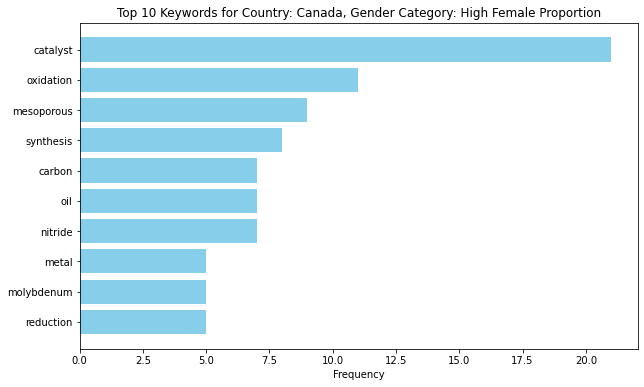

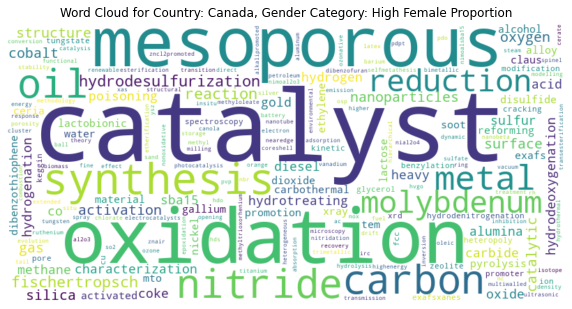

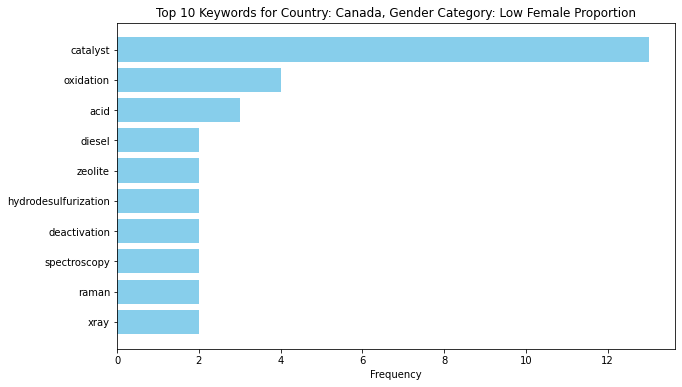

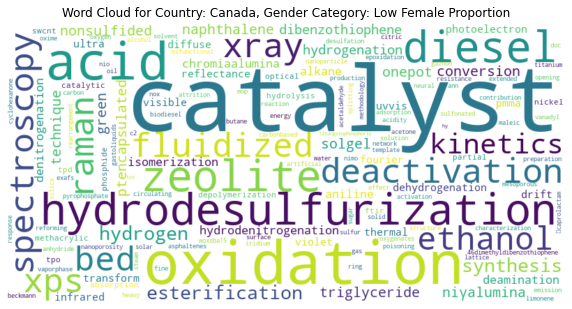

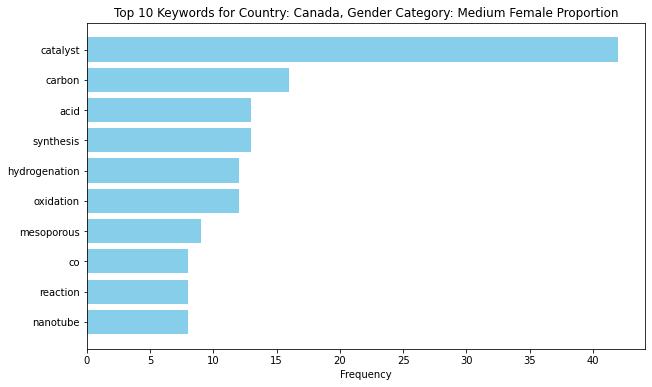

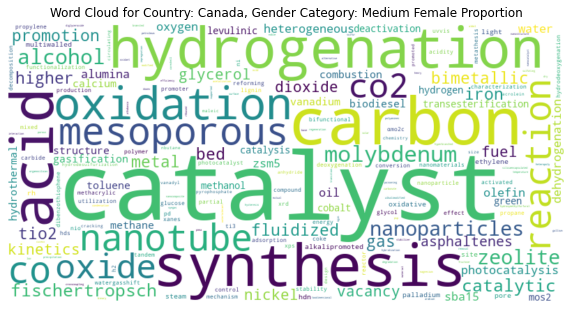

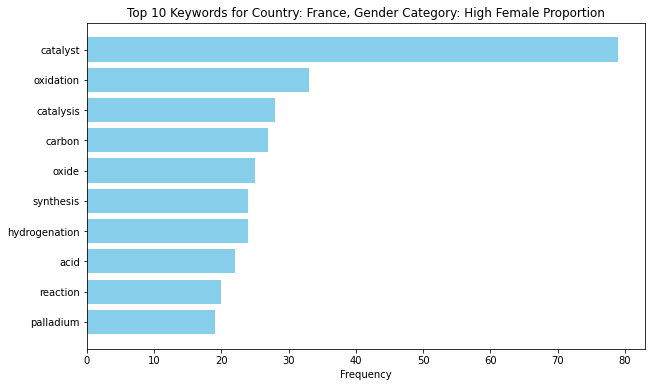

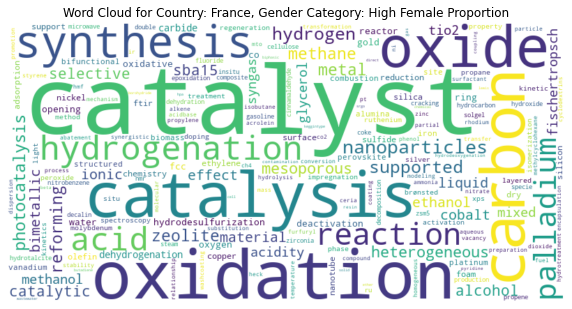

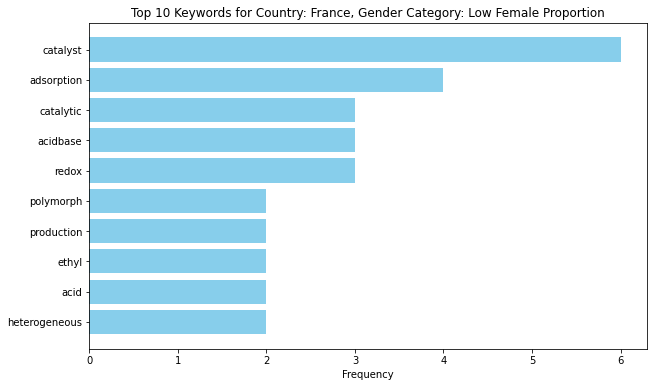

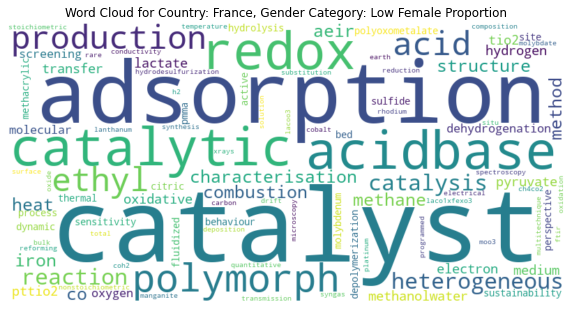

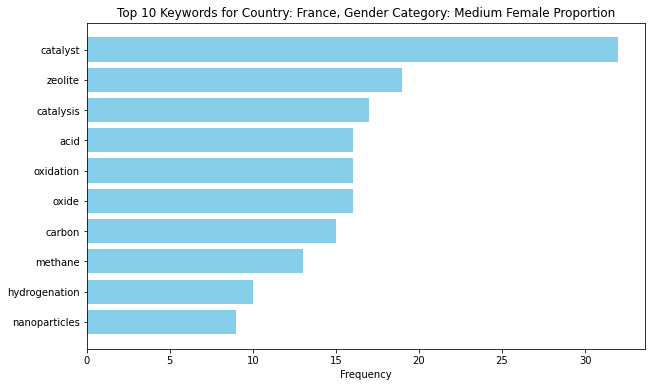

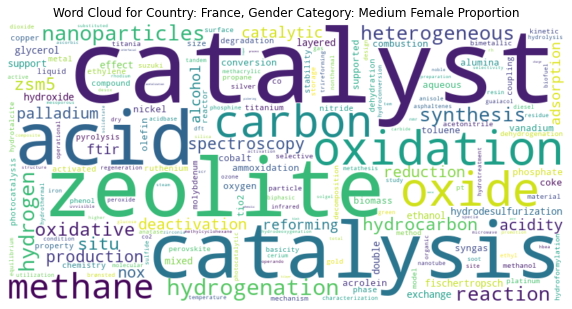

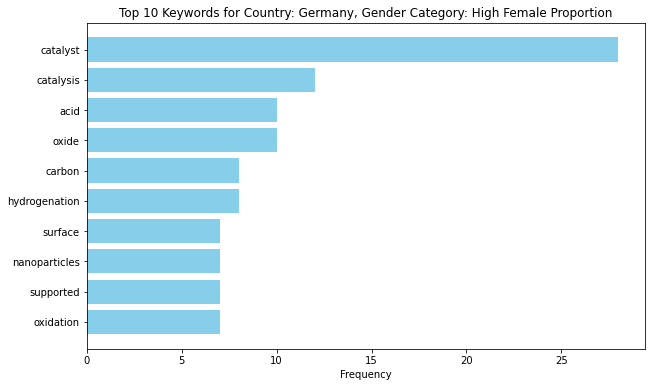

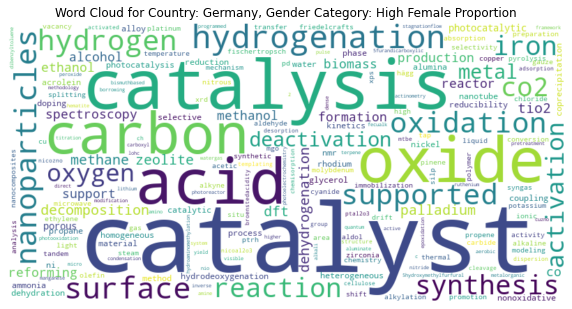

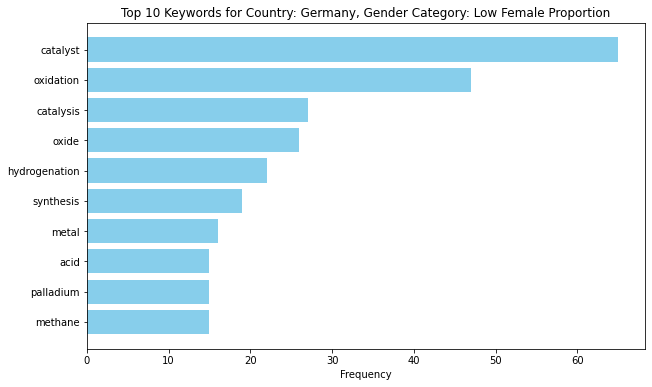

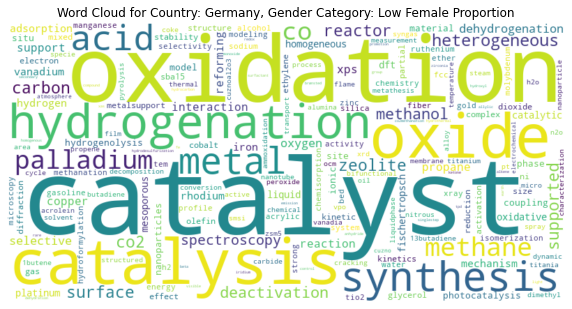

ValueError: not enough values to unpack (expected 2, got 0)

In [16]:
import matplotlib.pyplot as plt
from collections import Counter
from wordcloud import WordCloud

# Assuming 'grouped_data' is already generated as shown earlier

def plot_word_frequencies(group, title):
    # Extract keywords for the current group
    filtered_keywords = group['Keywords'].dropna().tolist()
    split_entities = [item.split(', ') for item in filtered_keywords]
    
    flat_entities = [entity for sublist in split_entities for entity in sublist]
    filtered_keywords_preprocessed = [preprocess_text(keyword) for keyword in flat_entities]
    tokenized_keywords = [keyword.split() for keyword in filtered_keywords_preprocessed]

    flat_tokens = [token for sublist in tokenized_keywords for token in sublist]
    word_frequencies = Counter(flat_tokens)
    
    # Create bar chart for top 10 words
    most_common_words = word_frequencies.most_common(10)
    words, frequencies = zip(*most_common_words)
    
    plt.figure(figsize=(10, 6))
    plt.barh(words, frequencies, color='skyblue')
    plt.xlabel('Frequency')
    plt.title(f"Top 10 Keywords for {title}")
    plt.gca().invert_yaxis()  # To have the highest frequency at the top
    plt.show()

def plot_word_cloud(group, title):
    # Extract keywords for the current group
    filtered_keywords = group['Keywords'].dropna().tolist()
    split_entities = [item.split(', ') for item in filtered_keywords]
    
    flat_entities = [entity for sublist in split_entities for entity in sublist]
    filtered_keywords_preprocessed = [preprocess_text(keyword) for keyword in flat_entities]
    tokenized_keywords = [keyword.split() for keyword in filtered_keywords_preprocessed]

    flat_tokens = [token for sublist in tokenized_keywords for token in sublist]
    word_frequencies = Counter(flat_tokens)
    
    # Generate the word cloud
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(word_frequencies)
    
    plt.figure(figsize=(10, 6))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f"Word Cloud for {title}")
    plt.show()

# Now, for each country and gender category, plot the word frequencies
for (country, gender_category), group in grouped_data:
    title = f"Country: {country}, Gender Category: {gender_category}"
    
    # Plot Bar chart for top keywords
    plot_word_frequencies(group, title)
    
    # Plot Word cloud for keywords
    plot_word_cloud(group, title)

In [ ]:
df = data
threshold = 0.75
filtered_df = df[df['ratio_female_authors'] >= threshold]
filtered_keywords = filtered_df['Keywords'].dropna().tolist() 

In [7]:
split_entities = [item.split(', ') for item in filtered_keywords]

flat_entities = [entity for sublist in split_entities for entity in sublist]

In [8]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    words = text.split()
    words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words]
    return ' '.join(words)

filtered_keywords_preprocessed = [preprocess_text(keyword) for keyword in flat_entities]

In [9]:
tokenized_keywords = [keyword.split() for keyword in filtered_keywords_preprocessed]

flat_tokens = [token for sublist in tokenized_keywords for token in sublist]

word_frequencies = Counter(flat_tokens)

most_common_words = word_frequencies.most_common()

for word, frequency in most_common_words:
    print(f"{word}: {frequency}")

catalyst: 300
oxidation: 119
oxide: 97
catalysis: 97
hydrogenation: 96
carbon: 92
synthesis: 87
acid: 86
nanoparticles: 69
reaction: 65
zeolite: 65
hydrogen: 60
methane: 55
reforming: 51
metal: 50
heterogeneous: 47
photocatalysis: 45
catalytic: 44
fischertropsch: 42
palladium: 41
cobalt: 40
reduction: 39
tio2: 38
surface: 37
supported: 37
mesoporous: 36
co: 36
bimetallic: 35
nickel: 34
oxygen: 33
deactivation: 33
alcohol: 32
dehydrogenation: 31
oxidative: 31
effect: 30
co2: 29
selective: 29
methanol: 28
mixed: 27
ethanol: 27
alumina: 26
water: 26
support: 26
molybdenum: 25
glycerol: 25
iron: 25
steam: 25
spectroscopy: 25
biomass: 24
gold: 24
liquid: 24
kinetics: 23
production: 23
nanotube: 22
olefin: 22
platinum: 22
carbide: 21
gas: 21
sba15: 21
ethylene: 21
decomposition: 21
phase: 21
dioxide: 20
hydrodeoxygenation: 20
material: 20
adsorption: 20
pyrolysis: 20
acidity: 20
site: 20
hydrodesulfurization: 19
activation: 19
silica: 19
zsm5: 19
alloy: 19
situ: 19
reactor: 19
vanadium: 18
s

In [10]:
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(flat_tokens)

num_topics = 4
lda = LatentDirichletAllocation(n_components=num_topics, random_state=42)
topic_weights = lda.fit_transform(X)

topic_keywords = []
for topic in lda.components_:
    top_word_indices = topic.argsort()[-5:][::-1]
    top_words = [vectorizer.get_feature_names_out()[i] for i in top_word_indices]
    topic_keywords.append(top_words)

for i, words in enumerate(topic_keywords):
    print(f"Topic {i + 1}: {', '.join(words)}")

Topic 1: nanoparticles, zeolite, methane, heterogeneous, photocatalysis
Topic 2: oxide, hydrogen, reforming, surface, co
Topic 3: catalyst, catalysis, hydrogenation, carbon, acid
Topic 4: oxidation, synthesis, metal, catalytic, fischertropsch


In [11]:
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(flat_tokens)

start_topic_num = 2
end_topic_num = 10

coherence_scores = []
for num_topics in range(start_topic_num, end_topic_num + 1):
    lda = LatentDirichletAllocation(n_components=num_topics, random_state=42)
    topic_weights = lda.fit_transform(X)

    topic_keywords = []
    for topic in lda.components_:
        top_word_indices = topic.argsort()[-5:][::-1]
        top_words = [vectorizer.get_feature_names_out()[i] for i in top_word_indices]
        topic_keywords.append(top_words)

    cosine_sim = cosine_similarity(topic_weights)

    coherence_score = sum([cosine_sim[i, j] for i in range(num_topics) for j in range(i + 1, num_topics)]) / (num_topics * (num_topics - 1))
    coherence_scores.append(coherence_score)
    print(f"Number of Topics: {num_topics}, Coherence Score: {coherence_score:.4f}")

optimal_num_topics = range(start_topic_num, end_topic_num + 1)[coherence_scores.index(max(coherence_scores))]
print(f"Optimal Number of Topics: {optimal_num_topics}")

Number of Topics: 2, Coherence Score: 0.3034
Number of Topics: 3, Coherence Score: 0.3336
Number of Topics: 4, Coherence Score: 0.3096
Number of Topics: 5, Coherence Score: 0.2500
Number of Topics: 6, Coherence Score: 0.2333
Number of Topics: 7, Coherence Score: 0.2000
Number of Topics: 8, Coherence Score: 0.1623
Number of Topics: 9, Coherence Score: 0.1458
Number of Topics: 10, Coherence Score: 0.1667
Optimal Number of Topics: 3


In [24]:
def analyse_topics(data, threshold=0.5, num_topics=4):
    filtered_df = data[data['ratio_male_authors'] >= threshold]
    
    filtered_keywords = filtered_df['Keywords'].dropna().tolist()
    split_entities = [item.split(', ') for item in filtered_keywords]

    lemmatizer = WordNetLemmatizer()
    stop_words = set(stopwords.words('english'))
      
    filtered_keywords_preprocessed = [preprocess_text(keyword) for sublist in split_entities for keyword in sublist]

    tokenized_keywords = [keyword.split() for keyword in filtered_keywords_preprocessed]

    flat_tokens = [token for sublist in tokenized_keywords for token in sublist]

    word_frequencies = Counter(flat_tokens)

    most_common_words = word_frequencies.most_common()

    for word, frequency in most_common_words:
        print(f"{word}: {frequency}")
    
    vectorizer = CountVectorizer()
    X = vectorizer.fit_transform(flat_tokens)

    lda = LatentDirichletAllocation(n_components=num_topics, random_state=42)
    topic_weights = lda.fit_transform(X)

    topic_keywords = []
    for topic in lda.components_:
        top_word_indices = topic.argsort()[-5:][::-1]
        top_words = [vectorizer.get_feature_names_out()[i] for i in top_word_indices]
        topic_keywords.append(top_words)

    for i, words in enumerate(topic_keywords):
        print(f"Topic {i + 1}: {', '.join(words)}")

In [25]:
df = data[data['Publication Title'] == 'Solar Energy']

df = df[['Keywords', 'ratio_female_authors', 'ratio_male_authors']]
analyse_topics(df, threshold=0.25, num_topics=5)

solar: 140
energy: 46
cell: 42
thermal: 40
heat: 38
pv: 33
photovoltaic: 33
efficiency: 22
system: 19
collector: 19
temperature: 18
building: 17
pvt: 16
transfer: 16
simulation: 15
photovoltaics: 15
module: 15
storage: 14
power: 14
model: 13
optical: 13
concentrator: 12
analysis: 11
concentrating: 11
irradiance: 10
bipv: 10
material: 9
vacuum: 9
performance: 9
modelling: 9
water: 8
glazing: 8
cooling: 8
heating: 8
experimental: 8
absorber: 7
cdte: 7
optimization: 7
renewable: 7
distribution: 7
natural: 7
pond: 7
design: 6
panel: 6
integrated: 6
stability: 6
phase: 6
change: 6
evacuated: 6
flat: 6
perovskite: 6
organic: 6
silicon: 6
hot: 6
degradation: 6
algorithm: 6
film: 6
desalination: 6
radiation: 6
ray: 6
absorption: 6
nanofluids: 5
learning: 5
image: 5
window: 5
glass: 5
electrical: 5
optimisation: 5
plate: 5
dssc: 5
reliability: 5
stress: 5
method: 5
management: 5
pump: 5
pcm: 5
high: 5
fresnel: 5
fluid: 5
dynamic: 5
light: 5
iv: 5
surface: 5
convection: 5
cavity: 5
concentration

Topic 1: transfer, pvt, module, simulation, experimental
Topic 2: solar, energy, pv, temperature, photovoltaics
Topic 3: cell, thermal, efficiency, collector, system
Topic 4: heat, photovoltaic, building, power, glazing
Topic 5: concentrator, concentrating, analysis, bipv, heating


In [51]:
def analyse_topics_with_NMF_female(data, threshold=0.5, num_topics=5):
    
    filtered_df = data[data['ratio_female_authors'] >= threshold]
    
    filtered_keywords = filtered_df['Keywords'].dropna().tolist()
    split_entities = [item.split(', ') for item in filtered_keywords]
    
    lemmatizer = WordNetLemmatizer()
    stop_words = set(stopwords.words('english'))
    
    filtered_keywords_preprocessed = [preprocess_text(keyword) for sublist in split_entities for keyword in sublist]

    tokenized_keywords = [keyword.split() for keyword in filtered_keywords_preprocessed]

    flat_tokens = [token for sublist in tokenized_keywords for token in sublist]

    word_frequencies = Counter(flat_tokens)

    most_common_words = word_frequencies.most_common()
    
    print(f"Threshold: {threshold} \n")

    for word, frequency in most_common_words[:12]:
        print(f"{word}: {frequency}")
    
    vectorizer = TfidfVectorizer()
    X = vectorizer.fit_transform(filtered_keywords_preprocessed)

    nmf = NMF(n_components=num_topics, max_iter=500, random_state=42)
    topic_weights = nmf.fit_transform(X)

    topic_keywords = []
    for topic in nmf.components_:
        top_word_indices = topic.argsort()[-5:][::-1]
        top_words = [vectorizer.get_feature_names_out()[i] for i in top_word_indices]
        topic_keywords.append(top_words)

    for i, words in enumerate(topic_keywords):
        print(f"{i + 1}: {', '.join(words)}")

analyse_topics_with_NMF_female(data, threshold=0.25, num_topics=4)
analyse_topics_with_NMF_female(data, threshold=0.5, num_topics=4)
analyse_topics_with_NMF_female(data, threshold=0.75, num_topics=4)

Threshold: 0.25 

hydrogen: 231
solar: 191
cell: 155
storage: 138
co2: 121
fuel: 113
carbon: 98
energy: 90
capture: 75
thermal: 68
heat: 66
gas: 60
1: hydrogen, production, storage, safety, combustion
2: storage, carbon, capture, dioxide, postcombustion
3: fuel, cell, solid, oxide, pem
4: co2, storage, leakage, sequestration, injection
Threshold: 0.5 

solar: 161
hydrogen: 92
cell: 86
storage: 67
energy: 52
thermal: 48
co2: 47
heat: 47
carbon: 45
fuel: 38
capture: 32
simulation: 31
1: hydrogen, production, storage, safety, generation
2: carbon, capture, storage, dioxide, postcombustion
3: fuel, cell, solar, oxide, solid
4: co2, storage, leakage, release, gas
Threshold: 0.75 

solar: 66
cell: 24
thermal: 21
energy: 20
heat: 18
storage: 16
concentrator: 14
performance: 13
efficiency: 13
hydrogen: 12
water: 11
building: 11
1: hydrogen, production, blue, green, storage
2: cell, fuel, orientation, opencathode, perovskite
3: solar, thermal, energy, heat, material
4: storage, co2, carbon, cap

In [53]:
def analyse_topics_with_NMF_male(data, threshold=0.5, num_topics=5):
    
    filtered_df = data[data['ratio_male_authors'] >= threshold]
    
    filtered_keywords = filtered_df['Keywords'].dropna().tolist()
    split_entities = [item.split(', ') for item in filtered_keywords]
    
    lemmatizer = WordNetLemmatizer()
    stop_words = set(stopwords.words('english'))
    
    filtered_keywords_preprocessed = [preprocess_text(keyword) for sublist in split_entities for keyword in sublist]

    tokenized_keywords = [keyword.split() for keyword in filtered_keywords_preprocessed]

    flat_tokens = [token for sublist in tokenized_keywords for token in sublist]

    word_frequencies = Counter(flat_tokens)

    most_common_words = word_frequencies.most_common()
    
    print(f"Threshold: {threshold}")

    for word, frequency in most_common_words[:12]:
        print(f"{word}: {frequency}")
    
    vectorizer = TfidfVectorizer()
    X = vectorizer.fit_transform(filtered_keywords_preprocessed)

    nmf = NMF(n_components=num_topics, max_iter=500, random_state=42)
    topic_weights = nmf.fit_transform(X)

    topic_keywords = []
    for topic in nmf.components_:
        top_word_indices = topic.argsort()[-5:][::-1]
        top_words = [vectorizer.get_feature_names_out()[i] for i in top_word_indices]
        topic_keywords.append(top_words)

    for i, words in enumerate(topic_keywords):
        print(f"{i + 1}: {', '.join(words)}")

analyse_topics_with_NMF_male(data, threshold=0.25, num_topics=4)
analyse_topics_with_NMF_male(data, threshold=0.5, num_topics=4)
analyse_topics_with_NMF_male(data, threshold=0.75, num_topics=4)

Threshold: 0.25
hydrogen: 496
storage: 254
cell: 242
fuel: 216
co2: 214
carbon: 181
solar: 161
energy: 147
capture: 144
catalyst: 120
gas: 119
model: 99
1: hydrogen, production, storage, safety, evolution
2: storage, carbon, capture, energy, dioxide
3: fuel, cell, solid, oxide, pem
4: co2, capture, leakage, storage, sequestration
Threshold: 0.5
hydrogen: 467
storage: 229
fuel: 205
cell: 204
co2: 192
carbon: 166
capture: 133
energy: 118
catalyst: 112
gas: 107
model: 87
solar: 84
1: hydrogen, production, storage, safety, evolution
2: storage, carbon, capture, energy, dioxide
3: fuel, cell, solid, oxide, pem
4: co2, capture, leakage, injection, sequestration
Threshold: 0.75
hydrogen: 313
storage: 147
fuel: 128
cell: 124
co2: 123
carbon: 101
capture: 86
energy: 77
catalyst: 76
gas: 72
model: 60
water: 53
1: hydrogen, production, safety, storage, generation
2: storage, carbon, capture, energy, cc
3: fuel, cell, pem, solid, oxide
4: co2, capture, leakage, injection, postcombustion


In [49]:
analyse_topics_with_NMF_female(df, threshold=0.25, num_topics=3)
analyse_topics_with_NMF_female(df, threshold=0.5, num_topics=3)
analyse_topics_with_NMF_female(df, threshold=0.75, num_topics=3)

Threshold: 0.25 

solar: 182
cell: 54
energy: 53
heat: 53
thermal: 52
photovoltaic: 36
pv: 31
efficiency: 30
concentrator: 23
collector: 22
building: 21
storage: 21
1: heat, solar, energy, thermal, storage
2: cell, solar, perovskite, pv, cdte
3: concentrator, optical, compound, efficiency, parabolic
Threshold: 0.5 

solar: 159
cell: 48
energy: 46
heat: 45
thermal: 44
photovoltaic: 30
efficiency: 27
pv: 23
collector: 21
concentrator: 21
building: 19
storage: 19
1: heat, solar, collector, transfer, water
2: cell, solar, concentrator, efficiency, photovoltaic
3: energy, thermal, storage, material, change
Threshold: 0.75 

solar: 66
energy: 20
thermal: 20
heat: 18
cell: 16
concentrator: 14
efficiency: 13
performance: 12
building: 11
water: 10
optical: 10
storage: 10
1: thermal, storage, energy, material, change
2: concentrator, compound, optical, parabolic, performance
3: solar, cell, heat, efficiency, perovskite


In [50]:
analyse_topics_with_NMF_male(df, threshold=0.25, num_topics=3)
analyse_topics_with_NMF_male(df, threshold=0.5, num_topics=3)
analyse_topics_with_NMF_male(df, threshold=0.75, num_topics=3)

Threshold: 0.25
solar: 140
energy: 46
cell: 42
thermal: 40
heat: 38
pv: 33
photovoltaic: 33
efficiency: 22
system: 19
collector: 19
temperature: 18
building: 17
Topic 1: solar, energy, heat, thermal, collector
Topic 2: cell, solar, cdte, semitransparent, bipv
Topic 3: photovoltaic, pv, module, simulation, concentrator
Threshold: 0.5
solar: 64
heat: 24
energy: 20
thermal: 20
pv: 17
cell: 16
photovoltaic: 14
pvt: 13
collector: 13
temperature: 12
efficiency: 11
building: 9
Topic 1: collector, heat, solar, transfer, efficiency
Topic 2: cell, pv, iv, photovoltaic, model
Topic 3: solar, energy, pond, storage, pvt
Threshold: 0.75
solar: 14
thermal: 9
energy: 8
heat: 7
pv: 6
bipv: 5
system: 5
efficiency: 5
concentrating: 5
photovoltaic: 5
organic: 4
renewable: 4
Topic 1: energy, solar, heat, thermal, efficiency
Topic 2: pv, curve, circuital, iv, model
Topic 3: graded, bandgap, cd, cdte, cdcl2ga2so43
